In [10]:
import os
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader

from langchain_openai import OpenAIEmbeddings, ChatOpenAI
from langchain_community.retrievers import PineconeHybridSearchRetriever
from pinecone import Pinecone, ServerlessSpec
from pinecone_text.sparse import BM25Encoder
from langchain_text_splitters import RecursiveCharacterTextSplitter


load_dotenv()

True

In [3]:
embeddings = OpenAIEmbeddings(
    model="text-embedding-3-small",
    openai_api_key=os.getenv("OPENROUTER_API_KEY"),
    openai_api_base="https://openrouter.ai/api/v1",
    dimensions=512
)

In [19]:
index_name = "learning-hybrid-search-index"

pc = Pinecone(api_key=os.getenv("PINECONE_API_KEY"))

if index_name not in pc.list_indexes().names():
    pc.create_index(
        name = index_name,
        dimension=512,
        metric='dotproduct'
    )

In [20]:
index = pc.Index(index_name)
index

Index(host='https://learning-hybrid-search-index-xia98fk.svc.aped-4627-b74a.pinecone.io')

In [16]:
docs = PyPDFLoader("../data/Company_Policies.pdf").load()+PyPDFLoader("../data/Company_Profile.pdf").load() + PyPDFLoader("../data/Product_and_pricing.pdf").load()
# docs = PyPDFLoader("../data/Company_Policies.pdf").load()

chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

texts = [d.page_content for d in chunks]

bm25 = BM25Encoder()
bm25.fit(texts)

100%|██████████| 13/13 [00:00<00:00, 253.18it/s]


In [21]:
retriever=PineconeHybridSearchRetriever(embeddings=embeddings, sparse_encoder=bm25,index=index)
retriever

PineconeHybridSearchRetriever(embeddings=OpenAIEmbeddings(client=<openai.resources.embeddings.Embeddings object at 0x000002AE4A7171D0>, async_client=<openai.resources.embeddings.AsyncEmbeddings object at 0x000002AE4A92CD10>, model='text-embedding-3-small', dimensions=512, deployment='text-embedding-ada-002', openai_api_version=None, openai_api_base='https://openrouter.ai/api/v1', openai_api_type=None, openai_proxy=None, embedding_ctx_length=8191, openai_api_key=SecretStr('**********'), openai_organization=None, allowed_special=None, disallowed_special=None, chunk_size=1000, max_retries=2, request_timeout=None, headers=None, tiktoken_enabled=True, tiktoken_model_name=None, show_progress_bar=False, model_kwargs={}, skip_empty=False, default_headers=None, default_query=None, retry_min_seconds=4, retry_max_seconds=20, http_client=None, http_async_client=None, check_embedding_ctx_length=True), sparse_encoder=<pinecone_text.sparse.bm25_encoder.BM25Encoder object at 0x000002AE4C541750>, index

In [22]:
retriever.add_texts(texts)

100%|██████████| 1/1 [00:08<00:00,  8.97s/it]


In [27]:
retriever.invoke("what is number of people working")

[Document(metadata={'score': 0.226519287}, page_content='NexaAI Solutions – Company Policies\nHR Policies\nNexaAI is committed to maintaining a fair, inclusive, and performance-driven workplace.\nAll employment decisions are made without discrimination.\n\x7f\nEqual opportunity employer\n\x7f\nBi-annual performance reviews\n\x7f\nClear career progression framework\n\x7f\nStrict anti-harassment policy\nLeave Policy\nEmployees are encouraged to maintain a healthy work-life balance.\n\x7f\nAnnual Leave: 18 working days per year\n\x7f\nSick Leave: 10 working days per year\n\x7f\nCasual Leave: 6 working days per year\n\x7f\nMaternity Leave: As per statutory norms\n\x7f\nUnused annual leave may be carried forward up to 30 days\nWorkplace Conduct\nEmployees are expected to act professionally and ethically at all times.\n\x7f\nMaintain confidentiality of company and client information\n\x7f\nAvoid conflicts of interest\n\x7f\nNo acceptance of bribes or unethical gifts\n\x7f\nCompliance with in

In [29]:
from typing import List, TypedDict, Literal
import time
import os

from langchain_groq import ChatGroq
from pydantic import BaseModel, Field

from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END

In [33]:
class State(TypedDict):
    question : str
    need_retrieval: bool

    docs : list[Document]
    relevant_docs : list[Document]

    context: str
    answer : str

In [30]:
llm = ChatGroq(
    model="openai/gpt-oss-120b", 
    temperature=0.2,
    max_tokens=800
)

In [34]:
def retrieve(State):
    q = State["question"]
    return {"docs" : retriever.invoke(q)}

In [38]:
class RetrieveDecision(BaseModel):
    should_retrieve: bool = Field(
        ...,
        description="True if external documents are needed to answer reliably, else False."
    )
    
decide_retrieval_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You decide whether retrieval is needed.\n"
            "Return JSON that matches this schema:\n"
            "{{'should_retrieve': boolean}}\n\n"
            "Guidelines:\n"
            "- should_retrieve=True if answering requires specific facts, citations, or info likely not in the model.\n"
            "- should_retrieve=False for general explanations, definitions, or reasoning that doesn't need sources.\n"
            "- If unsure, choose True."
        ),
        ("human", "Question: {question}"),
    ]
)

should_retrieve_llm = llm.with_structured_output(RetrieveDecision)

def decide_retrieval(state: "state"):
    decision: RetrieveDecision = should_retrieve_llm.invoke(
        decide_retrieval_prompt.format_messages(question=state["question"])
    )
    return {"need_retrieval": decision.should_retrieve}

In [35]:
class RelvenceDecision(BaseModel):
    is_relevant : bool = Field(description="True if the document helps answer the question, else False.")

is_relevant_prompt = ChatPromptTemplate.from_messages(
    [   
        (
            "system",
            "You are judging document relevance.\n"
            "Return JSON that matches this schema:\n"
            "{{'is_relevant': boolean}}\n\n"
            "A document is relevant if it contains information useful for answering the question."
        ),
        (
            "human",
            "Question:\n{question}\n\nDocument:\n{document}"
        )
    ]
)

relvenceLLM = llm.with_structured_output(RelvenceDecision)

def is_relevent(state : State):
    relevent_docs : List[Document] = []

    for doc in state["docs"]:
        out = relvenceLLM.invoke(
            is_relevant_prompt.format_messages(
                question=state["question"],
                document=doc.page_content
            )
        )

        if out.is_relevant:
            relevent_docs.append(doc)
    
    return {"relevant_docs": relevent_docs} 

In [ ]:
# res = (is_relevant_prompt | relvenceLLM).invoke({"question":"hi","document": "doc"})

In [40]:
direct_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "Answer the question using only your general knowledge.\n"
            "Do NOT assume access to external documents.\n"
            "If you are unsure or the answer requires specific sources, say:\n"
            "'I don't know based on my general knowledge.'"
        ),
        ("human", "{question}"),
    ]
)


def generate_direct(state: State):
    out = llm.invoke(
        direct_generation_prompt.format_messages(
            question=state["question"]
        )
    )
    return {
        "answer": out.content
    }

In [41]:
def route_after_decision(state : State) -> Literal["retrieve", "generate_direct"]:
    if state["need_retrieval"]:
        return "retrieve"
    return "generate_direct"

In [42]:
rag_generation_prompt = ChatPromptTemplate.from_messages(
    [
        (
            "system",
            "You are a business RAG assistant.\n"
            "Answer the user's question using ONLY the provided context.\n"
            "If the context does not contain enough information, say:\n"
            "'No relevant document found.'\n"
            "Do not use outside knowledge.\n"
        ),
        (
            "human",
            "Question:\n{question}\n\n"
            "Context:\n{context}\n"
        ),
    ]
)

def generate_from_context(state: State):
    # Stuff relevant docs into one block
    context = "\n\n---\n\n".join(
        [d.page_content for d in state.get("relevant_docs", [])]
    ).strip()

    if not context:
        return {"answer": "No relevant document found.", "context": ""}

    out = llm.invoke(
        rag_generation_prompt.format_messages(
            question=state["question"],
            context=context
        )
    )
    return {"answer": out.content, "context": context}

In [44]:
graph = StateGraph(State)
graph.add_node("retrieve", retrieve)

graph.add_node("decide_retrieval", decide_retrieval)

graph.add_node("generate_direct", generate_direct)
graph.add_node("is_relevant", is_relevent)
graph.add_node("generate_from_context", generate_from_context)


graph.add_edge(START, "decide_retrieval")
graph.add_conditional_edges("decide_retrieval", route_after_decision,{
    "generate_direct":"generate_direct",
    "retrieve": "retrieve"
}
)

graph.add_edge("retrieve", "is_relevant")
graph.add_edge("is_relevant", "generate_from_context")
graph.add_edge("generate_from_context", END)
graph.add_edge("generate_direct", END)

app = graph.compile()

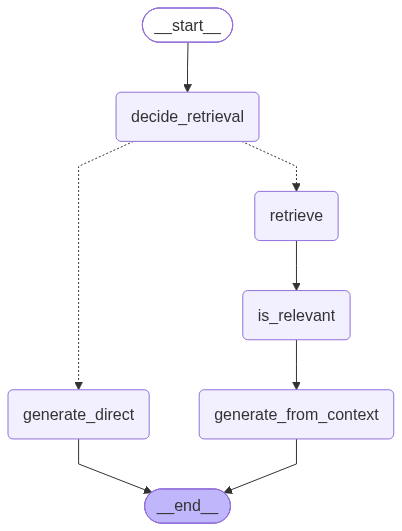

In [45]:
app

In [51]:
res = app.invoke({"question": "what is number of employees working in org","need_retrieval": 0, "docs": [], "relevant_docs":[], "answer": ""})


In [52]:
res

{'question': 'what is number of employees working in org',
 'need_retrieval': True,
 'docs': [Document(metadata={'score': 0.277623475}, page_content='NexaAI Solutions – Company Policies\nHR Policies\nNexaAI is committed to maintaining a fair, inclusive, and performance-driven workplace.\nAll employment decisions are made without discrimination.\n\x7f\nEqual opportunity employer\n\x7f\nBi-annual performance reviews\n\x7f\nClear career progression framework\n\x7f\nStrict anti-harassment policy\nLeave Policy\nEmployees are encouraged to maintain a healthy work-life balance.\n\x7f\nAnnual Leave: 18 working days per year\n\x7f\nSick Leave: 10 working days per year\n\x7f\nCasual Leave: 6 working days per year\n\x7f\nMaternity Leave: As per statutory norms\n\x7f\nUnused annual leave may be carried forward up to 30 days\nWorkplace Conduct\nEmployees are expected to act professionally and ethically at all times.\n\x7f\nMaintain confidentiality of company and client information\n\x7f\nAvoid conf